# <font color='#2E86C1' size=6>**Missing values: mechanisms, recoveries and imputation**</font>

**Workflow:** [01 Data cleaning](01_data_cleaning.ipynb) → [02 Customer table](02_customer_table.ipynb) → **03 Missing values** → [04 Outliers](04_outlier_detection.ipynb) → [05 Preprocessing recipe and models](05_preprocessing_and_models.ipynb) → [06 Feature engineering and selection](06_feature_engineering_selection.ipynb)

Every gap in the data: why it is there, and how it is filled without leaking information.

- **Sections 1–4:** the regression target's gaps, the treatment decision, the mechanism of the gaps that are left after the cleaning rules of notebook 01 (section 5), and a first comparison of imputers.
- **Sections 5–13:** an audit of that imputation, its fixes and their effect on the models.

### Imputation: exact recoveries, customer history and row limits

Notebook 01 (section 5) and sections 1–4 of this notebook fill the gaps in three layers: exact recovery from identities, structural fill for values that can't exist, and then a fitted imputer (median / most frequent) for whatever is left. An audit of that last layer found three weaknesses, which sections 5–9 fix and test:

1. **Missed exact recoveries.** With one or two previous purchases, the largest and smallest previous purchase follow from the total.
2. **The customer's own history was ignored.** Customers keep the same payment type, salesperson and transport method from one purchase to the next. The days since the previous purchase are simply the date difference to it, when that purchase is in the data.
3. **Imputed values could be impossible.** A single median ignores the rest of the row: it put the 365-day spend below the 180-day spend, or above everything the customer ever spent.

| Change | Code | Rule (`config.yaml`) |
|---|---|---|
| exact recoveries | `src/cleaning.py` → `apply_recompute_rules` | `diagnostics.recompute_rules` (4 new rules) |
| customer history | `src/cleaning.py` → `fill_from_customer_history` | `diagnostics.customer_history` |
| row limits | `src/preprocessing.py` → `RowBoundedImputer` | `preprocessing.imputation.row_bounds` |

A second round (sections 10–12) improves the values the fitted imputer still has to invent:

4. **Estimating `spend_365d` from related columns.** The 365-day purchase count is always known, so count × mean purchase value is a natural estimate. An iterative imputer limited to the spend and count columns is the alternative.
5. **Medians without the structural zeros, or by group.** On a first purchase, a 0 means "no history", and it pulls the median down.
6. **Settling the KNN decision.** Re-tested with a tuned random forest, 3 / 5 / 10 / 20 neighbours, uniform or distance weighting, and its extra fit time.

| Change | Code | Rule (`config.yaml`) |
|---|---|---|
| estimates from related columns | `src/preprocessing.py` → `RowBoundedImputer(column_imputers=…)` | `<task>.preprocessing.imputation.column_imputers` |
| medians without structural rows | `src/preprocessing.py` → `RowBoundedImputer(fit_rows=…)` | `preprocessing.imputation.fit_rows` |
| KNN neighbours and weights | `src/preprocessing.py` → `_numeric_imputer` | `imputation.n_neighbors`, `imputation.knn_weights` |

## Table of Contents <a class="anchor" id="toc"></a>
- [0. Setup](#setup)
- [1. Regression-target missingness](#target)
- [2. Missing-value treatment decision](#treatment)
- [3. Missingness mechanism of the remaining gaps](#mechanism)
- [4. Alternative imputers](#imputers-first)
- [5. What reaches the imputers](#gaps)
- [6. Exact recoveries of the largest / smallest previous purchase](#recoveries)
- [7. Filling from the customer's earlier purchases](#history)
- [8. Keeping imputed values within their row's limits](#bounds)
- [9. Does it help the models?](#models)
- [10. Better estimates for the last gaps](#estimates)
- [11. Alternative imputers, again](#imputers)
- [12. Settling KNN](#knn)
- [13. Summary](#summary)
- [14. From this notebook to the pipeline](#to-pipeline)

# <font color='#2E86C1' size=6>**0. Setup**</font> <a class="anchor" id="setup"></a>

[Back to TOC](#toc)

In [1]:
import copy
import os
import sys
import time
from pathlib import Path

# run from the project root, whether Jupyter was started there or in notebooks/
ROOT = Path.cwd() if (Path.cwd() / "config.yaml").exists() else Path.cwd().parent
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import yaml
from scipy import stats
from sklearn.impute import KNNImputer, SimpleImputer
from sklearn.preprocessing import MinMaxScaler

from src.cleaning import drop_training_rows, fill_from_customer_history, flag_invalid_values, prepare_table
from src.data import load_data, standardize_columns, standardize_dtypes
from src.evaluate import compare_preprocessing_variants, cross_validate_pipeline, paired_comparison, select_scoring, temporal_folds
from src.pipeline import build_pipeline, prepare_task_data
from src.preprocessing import RowBoundedImputer, _numeric_imputer, build_preprocessor, task_preprocessing_config
from src.tasks import TASKS
from src.tuning import tune_pipeline
import classification.model as classification_model
import regression.model as regression_model

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)
with open("config.yaml", encoding="utf-8") as f:
    config = yaml.safe_load(f)
data_cfg, diag_cfg, prep_cfg = config["data"], config["diagnostics"], config["preprocessing"]
tokens = diag_cfg["placeholder_tokens"]
SCORING = {task: select_scoring(TASKS[task].evaluate.SCORING, config[task]["metrics"]) for task in TASKS}
TASK_MODELS = {"classification": classification_model, "regression": regression_model}


In [2]:
# sections 1-4 start from the purchase files as notebook 01 prepares them
train_raw = load_data(data_cfg["train_path"], tokens)
test_raw = load_data(data_cfg["test_path"], tokens)
clientes_raw = load_data(data_cfg["clientes_path"], tokens)

# the raw purchase rows with standard names, without the 65 almost-empty rows (notebook 01, sections 1 and 2.1)
train = standardize_columns(train_raw, diag_cfg["column_renames"])
almost_empty_columns = [column for column in train.columns if column not in diag_cfg["almost_empty_preserved_columns"]]
missing_pattern = train[almost_empty_columns].isna().all(axis=1)
history = train.loc[~missing_pattern]

# section 1: invalid values -> NaN, training-only rows removed, compact dtypes (notebook 01, sections 2.2-2.5)
train_clean = train.copy()
flag_invalid_values(train_clean, diag_cfg)
train_clean, _ = drop_training_rows(train_clean, diag_cfg, data_cfg["id_column"])
train_clean = standardize_dtypes(train_clean, config["dtypes"])

# section 3: after every stateless rule, before the customer-history fill (notebook 01, section 5.4)
train_rules, _ = prepare_table(train_raw, config, clientes_raw)
train_rules, _ = drop_training_rows(train_rules, diag_cfg, data_cfg["id_column"], config["customers"])

# section 4: each task's development set and temporal folds (notebook 01, sections 6-7)
splits, task_folds = {}, {}
for task in TASKS:
    d = prepare_task_data(config, task)
    splits[task] = (d["X_dev"], d["X_test"], d["y_dev"], d["y_test"], d["extras_dev"], d["extras_test"])
    task_folds[task] = temporal_folds(d["extras_dev"][data_cfg["date_column"]], config["cv"]["n_splits"], config["cv"]["gap_days"])


In [3]:
# sections 5-12: each change switched on or off, and the purchase tables before the new recoveries
NEW_RULE_COLUMNS = ("prior_max_purchase_value", "prior_min_purchase_value")


def variant(recover=True, history=True, bounds=True, structural_rows=True, estimates=True):
    """config.yaml with each change switched on or off."""
    cfg = copy.deepcopy(config)
    if not recover:
        cfg["diagnostics"]["recompute_rules"] = [r for r in cfg["diagnostics"]["recompute_rules"] if r["column"] not in NEW_RULE_COLUMNS]
    cfg["diagnostics"]["customer_history"]["use"] = history
    if not bounds:
        cfg["preprocessing"]["imputation"]["row_bounds"] = {}
    if not structural_rows:
        cfg["preprocessing"]["imputation"]["fit_rows"] = {}
    if not estimates:
        for task in TASKS:
            (cfg[task].get("preprocessing") or {}).get("imputation", {}).pop("column_imputers", None)
    return cfg


def with_imputation(cfg, task, **settings):
    """A copy of `cfg` with `task`'s imputation settings changed."""
    cfg = copy.deepcopy(cfg)
    cfg[task].setdefault("preprocessing", {}).setdefault("imputation", {}).update(settings)
    return cfg


def cv_scores(cfg, task, model_cfg=None):
    """Validation scores of `task` on the 5 temporal folds with config `cfg`."""
    d = prepare_task_data(cfg, task)
    folds = temporal_folds(d["extras_dev"][data_cfg["date_column"]], config["cv"]["n_splits"], config["cv"]["gap_days"])
    pipeline = build_pipeline(d["preprocessing_config"], TASKS[task].model.build_model(model_cfg or cfg[task]["model"]))
    metric = config[task]["selection_metric"]
    return cross_validate_pipeline(pipeline, d["X_dev"], d["y_dev"], folds, SCORING[task])[f"validation_{metric}"].to_numpy()


def with_seed(model_cfg, seed):
    return {**model_cfg, "params": {**model_cfg["params"], "random_state": seed}}


# the configuration after the first three changes (sections 5-9), before the second round (10-12)
round1 = variant(structural_rows=False, estimates=False)


def versus(scores_a, scores_b, higher_is_better):
    r = paired_comparison(scores_a, scores_b, higher_is_better)
    decisive = ", decisive" if r["decisive"] else ""
    return f"{r['mean_advantage']:+.4f} (SE {r['se']:.4f}, better on {r['folds_a_better']}/{r['n_folds']} folds{decisive})"


# the purchase tables after the stateless steps, WITHOUT the new recoveries (to check the identities
# on originally observed values); the 65 almost-empty training rows are not purchases
previous = variant(False, False, False, False, False)
clientes = load_data(data_cfg["clientes_path"], tokens)
train_prev, _ = prepare_table(load_data(data_cfg["train_path"], tokens), previous, clientes)
test_prev, _ = prepare_table(load_data(data_cfg["test_path"], tokens), previous, clientes)
purchases = pd.concat([train_prev.assign(file="train"), test_prev.assign(file="test")], ignore_index=True)
purchases = purchases[purchases["purchase_date"].notna()].sort_values(["customer_id", "purchase_date"]).reset_index(drop=True)
print(len(purchases), "purchases,", purchases["customer_id"].nunique(), "customers")

7455 purchases, 629 customers


# <font color='#2E86C1' size=6>**1. Regression-target missingness**</font> <a class="anchor" id="target"></a>

`spend_next_90d` is only defined for customers who come back, so it is missing for every non-repeater. That is structural and expected. The question is the repeaters whose spend is missing:

[Back to TOC](#toc)

In [4]:
# Create a categorical variable indicating whether the regression target is missing
spend_status = train_clean["spend_next_90d"].isna().map({
    True: "Missing",
    False: "Observed"
})

# Summarise missingness by the classification target
# Rows = repeat_purchase_90d; columns = missingness status
missingness_counts = pd.crosstab(
    train_clean["repeat_purchase_90d"],
    spend_status
)

# Calculate row percentages to compare missingness rates within each class
missingness_percentages = pd.crosstab(
    train_clean["repeat_purchase_90d"],
    spend_status,
    normalize="index"
).mul(100).round(2)

print("Counts:")
print(missingness_counts)

print("\nPercentages within each repeat_purchase_90d class:")
print(missingness_percentages)

Counts:
spend_next_90d       Missing  Observed
repeat_purchase_90d                   
0                       2848         0
1                        196      3425

Percentages within each repeat_purchase_90d class:
spend_next_90d       Missing  Observed
repeat_purchase_90d                   
0                     100.00      0.00
1                       5.41     94.59


Is *being missing* related to anything? The same tests as section 3 (Mann-Whitney for numeric features, χ² for categorical ones with categories under 30 rows grouped as `rare`, Bonferroni threshold), restricted to repeat purchasers:

In [5]:
repeaters = train_clean.loc[train_clean["repeat_purchase_90d"].eq(1)]
spend_missing = repeaters["spend_next_90d"].isna()

rows = []
for feature in prep_cfg["numeric_features"]:
    missing_values = repeaters.loc[spend_missing, feature].dropna()
    observed_values = repeaters.loc[~spend_missing, feature].dropna()
    rows.append({"feature": feature, "test": "Mann-Whitney",
                 "median_missing": missing_values.median(), "median_observed": observed_values.median(),
                 "p_value": stats.mannwhitneyu(missing_values, observed_values).pvalue})
for feature in prep_cfg["categorical_features"]:
    values = repeaters[feature].astype("object").fillna("missing")
    values = values.where(values.map(values.value_counts()).ge(30), "rare")
    rows.append({"feature": feature, "test": "chi-squared",
                 "p_value": stats.chi2_contingency(pd.crosstab(spend_missing, values))[1]})

target_missing_tests = pd.DataFrame(rows).sort_values("p_value").reset_index(drop=True)
threshold = 0.05 / len(target_missing_tests)
target_missing_tests["related"] = target_missing_tests["p_value"] < threshold
print(f"Repeat purchasers: {len(repeaters)}, spend missing: {int(spend_missing.sum())} ({100 * spend_missing.mean():.1f}%)")
print(f"{int(target_missing_tests['related'].sum())} of {len(target_missing_tests)} features are related to the missing spend "
      f"(Bonferroni threshold {threshold:.4f})")
display(target_missing_tests.head(10).round(4))

Repeat purchasers: 3621, spend missing: 196 (5.4%)
13 of 32 features are related to the missing spend (Bonferroni threshold 0.0016)


,feature,test,median_missing,median_observed,p_value,related
0,transport_method,chi-squared,NaN,NaN,0.0000,True
1,salesperson,chi-squared,NaN,NaN,0.0000,True
2,purchase_count_365d,Mann-Whitney,3.00,5.000,0.0000,True
3,purchase_count_180d,Mann-Whitney,2.00,3.000,0.0000,True
4,spend_365d,Mann-Whitney,1972.77,4644.405,0.0000,True
5,spend_180d,Mann-Whitney,1039.70,2166.490,0.0000,True
6,document_series,chi-squared,NaN,NaN,0.0001,True
7,prior_purchase_count,Mann-Whitney,8.50,17.000,0.0001,True
8,commercial_zone,chi-squared,NaN,NaN,0.0002,True
9,shipping_cost,Mann-Whitney,0.00,0.000,0.0002,True


purchase_date,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025
repeat_purchases,179.0,216.0,424.0,385.0,337.0,398.0,429.0,302.0,446.0,456.0,49.0
spend_missing_%,16.8,4.6,3.8,4.9,1.8,1.3,2.3,2.3,3.6,11.6,49.0


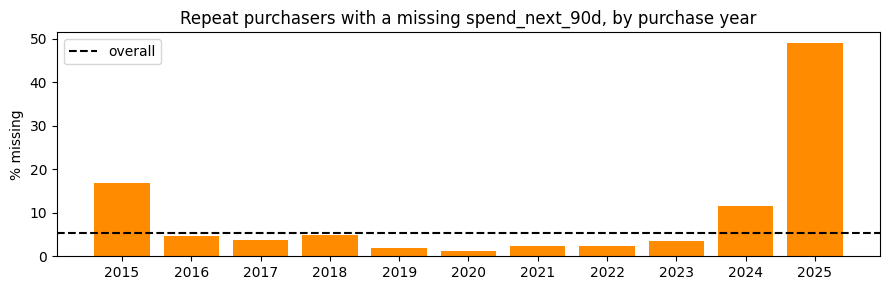

In [6]:
purchase_year = pd.to_datetime(repeaters["purchase_date"]).dt.year
by_year = pd.DataFrame({
    "repeat_purchases": purchase_year.value_counts().sort_index(),
    "spend_missing_%": spend_missing.groupby(purchase_year).mean().mul(100).round(1),
})
display(by_year.T)

fig, ax = plt.subplots(figsize=(9, 3))
ax.bar(by_year.index.astype(str), by_year["spend_missing_%"], color="darkorange")
ax.axhline(100 * spend_missing.mean(), linestyle="--", color="black", label="overall")
ax.set_title("Repeat purchasers with a missing spend_next_90d, by purchase year")
ax.set_ylabel("% missing")
ax.legend()
plt.tight_layout()
plt.show()

**Verdict: not MCAR.**

- **Strongly time-dependent.** The missing share is concentrated at the two edges of the data: the first year (2015) and especially the last months (2024, and about half of the 2025 purchases). In the years in between it is low. This looks like the 90-day spend not being fully recorded at the edges of the data extract.
- **Related to the customer profile.** Rows with a missing spend come from customers with a shorter, lower-value history (fewer prior purchases, lower 180/365-day spend) and are associated with several categorical features.

**Decision:** a target is never imputed. Inventing a label would mean training on our own guesses. The regressor trains only on repeat purchasers with an observed spend (`config.yaml` → `regression.row_filter`), and its preprocessing is fitted on those rows only (`regression.select_training_rows()`, notebook 01, section 6).

**Consequence to keep in mind:** the regression training rows slightly over-represent longer, higher-value histories, and the most recent months (the locked test period) have fewer usable regression rows. The regressor's errors should be read with that in mind.

# <font color='#2E86C1' size=6>**2. Missing-value treatment decision**</font> <a class="anchor" id="treatment"></a>

- **Broad missingness:** exclude the 65 training rows with a simultaneous, broad predictor-missingness pattern from model fitting (notebook 01, section 2.4). There is no equivalent complete pattern in `test.csv`, and imputation would invent most of a purchase record. Keep the raw rows for audit only.
- **Predictor missingness:** first recover what the identities, the consistency rules and the column definitions allow (notebook 01, sections 5.1–5.3), then test the mechanism of what is left (section 3). Imputation and missingness indicators are fitted on each training fold only, inside the model `Pipeline`, to avoid leakage.
- **Targets:** never impute either target. The classification target is complete. The spend target is missing for 5.4% of repeaters, and not at random (section 1). Train the spend regressor only on repeat purchasers with an observed `spend_next_90d` value.
- **Clientes:** if the optional customer table is merged later, drop `customer_type` because it is entirely missing; handle the other customer fields within the same fold-safe preprocessing pipeline.

[Back to TOC](#toc)

In [7]:
assert train_clean["repeat_purchase_90d"].notna().all()

eligible_repeaters = train_clean.loc[
    train_clean["repeat_purchase_90d"].eq(1)
].copy()
observed_regression_target = eligible_repeaters["spend_next_90d"].notna()

print("Classification training rows:", len(train_clean))
print("Regression training rows (observed spend only):", int(observed_regression_target.sum()))
print(
    "Repeat purchasers without an observed spend target:",
    int((~observed_regression_target).sum())
)

Classification training rows: 6469
Regression training rows (observed spend only): 3425
Repeat purchasers without an observed spend target: 196


# <font color='#2E86C1' size=6>**3. Missingness mechanism of the remaining gaps**</font> <a class="anchor" id="mechanism"></a>

After the rules, only real gaps are left. For each one we test whether *being missing* is related to the target or to any other feature:

- **target:** χ² test of missing/observed × `repeat_purchase_90d`;
- **numeric features:** Mann-Whitney U, missing rows vs observed rows;
- **categorical features:** χ² test, with categories under 30 rows grouped as `rare` so that sparse cells don't produce false signals.

Significance uses a Bonferroni threshold (0.05 / number of tests per column). No association → **MCAR** → a simple median/mode loses nothing. Association → **MAR/MNAR** → impute **and** add a `_was_missing` flag.

[Back to TOC](#toc)

In [8]:
def missingness_tests(df, columns, numeric, categorical, target, min_category_rows=30):
    rows = []
    for column in columns:
        missing = df[column].isna()
        target_p = stats.chi2_contingency(pd.crosstab(missing, df[target]))[1]

        p_values = {}
        for other in numeric:
            if other != column and df.loc[missing, other].notna().sum() > 5:
                p_values[other] = stats.mannwhitneyu(
                    df.loc[missing, other].dropna(), df.loc[~missing, other].dropna()
                ).pvalue
        for other in categorical:
            if other != column:
                values = df[other].astype("object").fillna("missing")
                counts = values.value_counts()
                values = values.where(values.map(counts).ge(min_category_rows), "rare")
                p_values[other] = stats.chi2_contingency(pd.crosstab(missing, values))[1]

        threshold = 0.05 / (len(p_values) + 1)
        related = [other for other, p in sorted(p_values.items(), key=lambda kv: kv[1]) if p < threshold]
        rows.append({
            "column": column,
            "missing_%": round(100 * missing.mean(), 2),
            "target_rate_missing": round(df.loc[missing, target].mean(), 3),
            "target_rate_observed": round(df.loc[~missing, target].mean(), 3),
            "target_p": round(target_p, 3),
            "related_features": ", ".join(related[:4]) or "none",
            "verdict": "MCAR" if target_p >= threshold and not related else "MAR/MNAR -> flag",
        })
    return pd.DataFrame(rows)


task_recipes = {task: task_preprocessing_config(config, task) for task in ["classification", "regression"]}
numeric_union = list(dict.fromkeys(f for r in task_recipes.values() for f in r["numeric_features"]))
categorical_union = list(dict.fromkeys(f for r in task_recipes.values() for f in r["categorical_features"]))
remaining_gaps = [c for c in numeric_union + categorical_union if train_rules[c].isna().any()]
mechanism_table = missingness_tests(
    train_rules, remaining_gaps, numeric_union, categorical_union,
    config["classification"]["target"],
)
display(mechanism_table)

,column,missing_%,target_rate_missing,target_rate_observed,target_p,related_features,verdict
0,days_since_previous_purchase,0.12,0.625,0.560,0.987,none,MCAR
1,prior_max_purchase_value,0.63,0.561,0.560,1.000,"transport_method, prior_std_gap_days",MAR/MNAR -> flag
2,prior_mean_gap_days,0.12,0.625,0.560,0.987,none,MCAR
3,spend_365d,2.81,0.582,0.559,0.583,"customer_tenure_days, years_as_customer, prior...",MAR/MNAR -> flag
4,payment_type,3.01,0.564,0.560,0.959,none,MCAR
5,salesperson,3.00,0.598,0.559,0.310,none,MCAR
6,transport_method,3.03,0.551,0.560,0.860,none,MCAR
7,warehouse,3.01,0.636,0.557,0.036,none,MCAR
8,commercial_region,0.48,0.387,0.561,0.078,"commercial_zone, country_or_region, island, pa...",MAR/MNAR -> flag
9,island,0.48,0.387,0.561,0.078,"commercial_zone, country_or_region, commercial...",MAR/MNAR -> flag


`spend_365d` shows up as related to tenure and history. Is that a property of the raw data, or a result of our own identity fill (notebook 01, section 5.1 fills it only for customers with ≤ 365 days of tenure)?

In [9]:
raw_spend_missing = history["spend_365d"].isna()
print("Raw data, tenure missing vs observed, Mann-Whitney p =",
      round(stats.mannwhitneyu(history.loc[raw_spend_missing, "customer_tenure_days"],
                               history.loc[~raw_spend_missing, "customer_tenure_days"]).pvalue, 3))
still_missing = train_rules["spend_365d"].isna()
print("After the rules, tenure of rows still missing: min",
      int(train_rules.loc[still_missing, "customer_tenure_days"].min()), "days")

Raw data, tenure missing vs observed, Mann-Whitney p = 0.84
After the rules, tenure of rows still missing: min 370 days


**Verdict table** (stored in `config.yaml` → `preprocessing` and `<task>.preprocessing`):

| Column | Missing after rules | Mechanism | Treatment (fitted on training rows only) |
|---|---|---|---|
| `days_since_previous_purchase`, `prior_mean_gap_days` | 8 rows (0.1%) | MCAR: no relation to target or features | median |
| `spend_365d` | 2.8% | MCAR in the raw data (tenure p = 0.84). After the identity fill, only customers with > 365 days of tenure stay missing, so it is related to tenure and history | median **+ a missing indicator** (`MissingIndicator` inside the pipeline, `mnar_indicator_sources`) |
| `prior_max_purchase_value` | 45 rows (0.7%) | these are the inflated maxima set to `NaN` in 5.2: repurchase rate 0.53 vs 0.56 (p = 0.84). The only association is with `transport_method`, a column with 80 levels | median, **no flag**: the gap marks a corrupted value, not a property of the customer, and a flag would teach the model to recognise the corruption |
| `payment_type`, `salesperson`, `transport_method`, `warehouse` | ~3% each, never on the same rows | MCAR: no relation to target or features once sparse categories are grouped | most frequent |
| `commercial_region`, `island`, `municipality` (customer table, regression only) | 0.5% / 0.5% / 3.4% | after the customer-table preprocessing (notebook 02): a blank island is structural ("not an island region" → `"none"`), and regions are recovered exactly from postal areas. What is left is a few incomplete customer profiles: related to other geography, and for `municipality` also to the target | an explicit `"Missing"` category (section 4), which acts as the missingness flag for a categorical column |
| history columns, first/early purchases | structural | not applicable (notebook 01, section 5.3) | 0 + `is_first_purchase` / `has_gap_history` |
| `spend_next_90d` (target) | all non-repeaters, 5.4% of repeaters | target, never imputed | regression trains on observed rows only |

An automatic `SimpleImputer(add_indicator=True)` would flag *every* column with gaps, including the MCAR ones, where a flag is only noise. We flag only where the evidence says the gap carries information.

# <font color='#2E86C1' size=6>**4. Alternative imputers**</font> <a class="anchor" id="imputers-first"></a>

Section 3 chose median / most frequent from the missingness mechanism. Is a smarter imputer better? Each option is fitted **inside each fold** (on training rows only), with the task's chosen recipe and model:
- **numeric:** `median` (current), `mean`, `constant` (0), `knn` (5 neighbours, after scaling so large-valued columns don't dominate the distances), `iterative` (each column regressed on the others, also after scaling);
- **categorical:** `most_frequent` vs an explicit `"Missing"` category (`constant`).

[Back to TOC](#toc)

In [10]:
def versus(scores_a, scores_b, higher_is_better):
    r = paired_comparison(scores_a, scores_b, higher_is_better)
    decisive = ", decisive" if r["decisive"] else ""
    return f"{r['mean_advantage']:+.4f} (SE {r['se']:.4f}, better on {r['folds_a_better']}/{r['n_folds']} folds{decisive})"


imputer_tables = {}
for task in ["classification", "regression"]:
    X_dev, _, y_dev, _, _, _ = splits[task]
    recipe = task_preprocessing_config(config, task)
    current = recipe["imputation"]
    variants = {f"numeric {s}": {**recipe, "imputation": {**current, "numeric_strategy": s}}
                for s in ["median", "mean", "constant", "knn", "iterative"]}
    other_categorical = "most_frequent" if current["categorical_strategy"] == "constant" else "constant"
    variants[f"categorical {other_categorical}"] = {**recipe, "imputation": {**current, "categorical_strategy": other_categorical}}
    metric = config[task]["selection_metric"]
    table, per_fold = compare_preprocessing_variants(
        variants, lambda: TASK_MODELS[task].build_model(config[task]["model"]), X_dev, y_dev, task_folds[task], SCORING[task], metric)
    reference = "numeric median"
    table["vs numeric median"] = [
        "" if v == reference else versus(per_fold[v], per_fold[reference], metric != "rmse") for v in table["variant"]
    ]
    imputer_tables[task] = table
    print(f"\n{task} (current: numeric {current['numeric_strategy']}, categorical {current['categorical_strategy']}): validation {metric}")
    display(table.round(4))


classification (current: numeric median, categorical most_frequent): validation accuracy


,variant,mean_accuracy,std_accuracy,vs numeric median
0,numeric iterative,0.7083,0.0153,"+0.0005 (SE 0.0006, better on 2/5 folds)"
1,numeric median,0.7078,0.0155,
2,numeric knn,0.7078,0.0161,"+0.0000 (SE 0.0013, better on 1/5 folds)"
3,categorical constant,0.7076,0.0170,"-0.0002 (SE 0.0010, better on 2/5 folds)"
4,numeric mean,0.7071,0.0174,"-0.0007 (SE 0.0010, better on 1/5 folds)"
5,numeric constant,0.7064,0.0165,"-0.0014 (SE 0.0006, better on 0/5 folds, decis..."



regression (current: numeric median, categorical constant): validation rmse


,variant,mean_rmse,std_rmse,vs numeric median
0,numeric mean,1942.2253,165.9460,"+0.2541 (SE 0.3624, better on 3/5 folds)"
1,numeric median,1942.4794,165.1851,
2,numeric iterative,1943.6122,166.3086,"-1.1328 (SE 0.9388, better on 2/5 folds)"
3,numeric knn,1943.9829,166.7986,"-1.5035 (SE 1.2392, better on 2/5 folds)"
4,numeric constant,1944.4845,166.8078,"-2.0051 (SE 1.5838, better on 0/5 folds)"
5,categorical most_frequent,1944.8946,163.7790,"-2.4152 (SE 1.1066, better on 1/5 folds, decis..."


**Verdict** (same rule: change only for a decisive gain with a sensible reason):
- **Classification:** the median stays. Every alternative is within 0.0014 accuracy of it. `constant` (0) is the only decisive one, and it is decisively **worse** (0 of 5 folds); 0 already means "not applicable" in this pipeline (structural fill, notebook 01, section 5.3) anyway.
- **Regression, numeric: the median stays, and the KNN question is closed.** KNN was once decisively better than the median here (6 RMSE, SE 3, all 5 folds). Section 12 found why: its neighbours gave a better 365-day spend. The pipeline now estimates that spend from the row itself (365-day purchase count × mean purchase value, section 10). With that estimate, the customer-history fill and the row limits, KNN is 1.5 RMSE **worse** (2 of 5 folds). Section 12 re-tested it with a tuned forest, 3 / 5 / 10 / 20 neighbours and distance weighting: never decisive. Mean, iterative and constant are within 2 RMSE.
- **Regression, categorical:** the explicit **`"Missing"` category** (`categorical_strategy: constant`) stays, now **decisively**: the most frequent value is 2.4 RMSE worse (SE 1.1), and `"Missing"` is better on 4 of 5 folds. The reason for it holds: the remaining customer gaps are incomplete profiles related to the target (section 3), and filling them with the most common region or municipality would hide that.

# <font color='#2E86C1' size=6>**5. What reaches the imputers**</font> <a class="anchor" id="gaps"></a>

Number of missing values left for the fitted imputers, per feature, before the three changes and after them. Development set (what the models learn from) and test.csv (what Kaggle scores).

[Back to TOC](#toc)

In [11]:
rows = []
for task in ["classification", "regression"]:
    before, after = prepare_task_data(previous, task), prepare_task_data(config, task)
    recipe = after["preprocessing_config"]
    features = recipe["numeric_features"] + recipe["categorical_features"]
    for name, part in [("development", "X_dev"), ("test.csv", "X_kaggle")]:
        b, a = before[part][features].isna().sum(), after[part][features].isna().sum()
        for column in b.index[(b > 0) | (a > 0)]:
            rows.append({"task": task, "set": name, "column": column, "before": int(b[column]), "after": int(a[column])})
gaps = pd.DataFrame(rows).pivot_table(index=["task", "column"], columns="set", values=["before", "after"], aggfunc="sum")
gaps = gaps[[("before", "development"), ("after", "development"), ("before", "test.csv"), ("after", "test.csv")]]
display(gaps)
print(gaps.groupby(level="task").sum())

before       after   before    after
set                                         development development test.csv test.csv
task           column                                                                
classification days_since_previous_purchase         6.0         0.0      NaN      NaN
               payment_type                       144.0        18.0     30.0      0.0
               prior_max_purchase_value            38.0        35.0      6.0      6.0
               prior_mean_gap_days                  6.0         0.0      NaN      NaN
               salesperson                        158.0        25.0     30.0      2.0
               spend_365d                         137.0       137.0     38.0     38.0
               transport_method                   153.0        22.0     30.0      0.0
               warehouse                          150.0        12.0     30.0      1.0
regression     commercial_region                    7.0         7.0      8.0      8.0
               days_since_previous_purchase         5.0         0.0      NaN      NaN
               island                               7.0         7.0      8.0      8.0
               municipality                        45.0        45.0     88.0     88.0
               payment_type                        83.0         3.0     30.0      0.0
               prior_max_purchase_value            18.0        17.0      6.0      6.0
               prior_mean_gap_days                  5.0         0.0      NaN      NaN
               salesperson                         90.0         8.0     30.0      2.0
               spend_365d                          76.0        76.0     38.0     38.0
               transport_method                    78.0         6.0     30.0      0.0
               warehouse                           93.0         5.0     30.0      1.0

                    before       after   before    after
set            development development test.csv test.csv
task                                                    
classification       792.0       249.0    164.0     47.0
regression           507.0       174.0    268.0    151.0


**About two thirds of the gaps no longer reach an imputer:**
- classification development set: 792 → 249;
- regression development set: 507 → 174;
- test.csv: 164 → 47 (classification features) and 268 → 151 (regression features).

Almost all of it comes from the customer history (section 7):
- each transaction category drops from about 150 gaps to 12–25 on the development set, and to 0–2 on test.csv;
- every gap in `days_since_previous_purchase` and `prior_mean_gap_days` is filled exactly.

**What is left for the fitted imputers:**
- `spend_365d` (137): keeps its missing indicator, and its imputed values are now bounded (section 8);
- `prior_max_purchase_value` (35): also bounded;
- the customer-table geography (regression only);
- the categories of purchases whose customer has no earlier known value.

# <font color='#2E86C1' size=6>**6. Exact recoveries of the largest / smallest previous purchase**</font> <a class="anchor" id="recoveries"></a>

With **one** previous purchase, that purchase is at once the smallest, the largest and the total. With **two**, smallest + largest = total. Each identity is checked on the rows where all its terms were observed (before the new rules), exactly like the identities of notebook 01, section 5.1.

[Back to TOC](#toc)

In [12]:
close = lambda a, b: (a - b).abs() <= 0.01
p = purchases
one, two = p["prior_purchase_count"] == 1, p["prior_purchase_count"] == 2
checks = []
for name, mask, left, right in [
    ("1 previous purchase: max = total", one, p["prior_max_purchase_value"], p["prior_total_spend"]),
    ("1 previous purchase: min = total", one, p["prior_min_purchase_value"], p["prior_total_spend"]),
    ("2 previous purchases: max + min = total", two, p["prior_max_purchase_value"] + p["prior_min_purchase_value"], p["prior_total_spend"]),
]:
    observed = mask & left.notna() & right.notna()
    checks.append({"identity": name, "rows checked": int(observed.sum()), "holds (%)": round(100 * close(left, right)[observed].mean(), 2)})
display(pd.DataFrame(checks))

recovered = []
for file, path in [("train.csv", data_cfg["train_path"]), ("test.csv", data_cfg["test_path"])]:
    _, report = prepare_table(load_data(path, tokens), config, clientes)
    new = report[report["column"].isin(NEW_RULE_COLUMNS) & report["step"].eq("recomputed from identity")]
    recovered.append(new.groupby("column")["values"].sum().rename(file))
display(pd.concat(recovered, axis=1).fillna(0).astype(int))
print("missing prior_max_purchase_value by number of previous purchases (before):",
      p.loc[p["prior_max_purchase_value"].isna(), "prior_purchase_count"].clip(upper=3).value_counts().sort_index().rename({3: "3+"}).to_dict())

,identity,rows checked,holds (%)
0,1 previous purchase: max = total,466,100.0
1,1 previous purchase: min = total,469,100.0
2,2 previous purchases: max + min = total,387,100.0


,train.csv,test.csv
column,,
prior_max_purchase_value,4,0


missing prior_max_purchase_value by number of previous purchases (before): {np.int16(1): 3, np.int16(2): 1, '3+': 47}


The three identities hold on **100%** of the rows where they can be checked (466, 469 and 387 rows). So they are exact definitions, like the identities of notebook 01, section 5.1.

- **4 of the 51 missing `prior_max_purchase_value` are recovered:** the 3 with one previous purchase and the 1 with two.
- **The other 47 can't be:** they have three or more previous purchases, where the largest one doesn't follow from the other columns. They stay for the fitted imputer, now with row limits (section 8).
- **`prior_min_purchase_value`** has no gap among real purchases today. Its two rules cover future records.

# <font color='#2E86C1' size=6>**7. Filling from the customer's earlier purchases**</font> <a class="anchor" id="history"></a>

`fill_from_customer_history()` uses only the **same customer's earlier purchases**: never a later one, and never a target. This is the information a system has when a purchase is made, the same kind as the `prior_*` columns. It runs after the stateless steps, on every known purchase (train.csv + test.csv), and leaves whatever it can't fill to the fitted imputers.

### 7.1 Categories: the customer's last observed value

How good would this fill be? Take every purchase whose value **is** known and has an earlier purchase of the same customer with a known value, then compare the actual value with:
- the customer's **last observed value**;
- the **most frequent** value overall, which is what the current imputer would use.

[Back to TOC](#toc)

In [13]:
rules = diag_cfg["customer_history"]
by_customer = purchases.groupby("customer_id", sort=False)
quality = []
for column in rules["last_observed_columns"]:
    last = by_customer[column].shift(1).astype(object).groupby(purchases["customer_id"]).ffill()
    known = purchases[column].notna() & last.notna()
    quality.append({
        "column": column,
        "purchases compared": int(known.sum()),
        "last observed value is right (%)": round(100 * (purchases[column] == last)[known].mean(), 1),
        "most frequent value is right (%)": round(100 * (purchases[column] == purchases[column].mode()[0])[known].mean(), 1),
        "gaps": int(purchases[column].isna().sum()),
        "gaps with an earlier value": int((purchases[column].isna() & last.notna()).sum()),
    })
display(pd.DataFrame(quality).set_index("column"))

,purchases compared,last observed value is right (%),most frequent value is right (%),gaps,gaps with an earlier value
column,,,,,
payment_type,6607,97.0,72.7,225,206
salesperson,6613,95.5,63.6,224,197
transport_method,6605,80.9,16.7,226,203
warehouse,6604,99.4,99.7,225,211
commercial_zone,6826,98.7,93.2,0,0
document_series,6826,80.7,52.2,0,0


- **The customer's last value is right far more often than the most frequent value:**

  | Column | Last value right | Most frequent value right |
  |---|---|---|
  | payment type | 97% | 73% |
  | salesperson | 96% | 64% |
  | transport method | 81% | 17% |
  | document series | 81% | 52% |
- **Warehouse is a tie** (99.4% vs 99.7%): almost every purchase uses the same warehouse, so both fills give the same value. It is filled from history anyway, to keep one consistent rule.
- **197–211 of the ~225 gaps in each transaction category** have an earlier value for the same customer. The rest belong to a customer's first known purchase and stay for the fitted imputer.
- **`commercial_zone` and `document_series`** have no gaps among real purchases today. The rule covers future records.

These gaps aren't "missing completely at random" in a useful sense. Which value is missing is explained by **who the customer is** (MAR given the customer), and the customer's own past is the best estimate. Section 3 found no link between the gaps and the target or the other columns of the same row, which is still true: the information is in the customer's other rows.

### 7.2 Days since the previous purchase: a date difference

When the customer's previous purchase is in the data (its prior purchase count is exactly one lower), `days_since_previous_purchase` should be the number of days between the two purchase dates. The recompute rules then run again, so `prior_mean_gap_days` follows from it.

In [14]:
previous_count = by_customer["prior_purchase_count"].shift(1)
consecutive = (purchases["prior_purchase_count"] - previous_count) == 1
date_gap = (purchases["purchase_date"] - by_customer["purchase_date"].shift(1)).dt.days
observed = consecutive & purchases["days_since_previous_purchase"].notna()
print(f"consecutive purchases with an observed gap: {int(observed.sum())}; "
      f"gap = date difference on {100 * ((date_gap - purchases['days_since_previous_purchase']).abs() <= 0.5)[observed].mean():.1f}%")
missing = purchases["days_since_previous_purchase"].isna()
print(f"missing gaps: {int(missing.sum())}, of which the previous purchase is in the data: {int((missing & consecutive).sum())}")

# the tables as the pipeline prepares them (exact recoveries included), before the history fill
train_now, _ = prepare_table(load_data(data_cfg["train_path"], tokens), config, clientes)
test_now, _ = prepare_table(load_data(data_cfg["test_path"], tokens), config, clientes)
history = pd.concat([train_now, test_now], ignore_index=True)
reports = []
for file, table in [("train.csv", train_now), ("test.csv", test_now)]:
    _, report = fill_from_customer_history(table, history, diag_cfg, data_cfg["id_column"])
    reports.append(report.groupby(["step", "column"])["values"].sum().rename(file))
display(pd.concat(reports, axis=1).fillna(0).astype(int))

consecutive purchases with an observed gap: 6669; gap = date difference on 100.0%
missing gaps: 8, of which the previous purchase is in the data: 8


train.csv  test.csv
step                                              column                                           
filled from the customer's last earlier purchase  payment_type                        176        30
                                                  salesperson                         169        28
                                                  transport_method                    173        30
                                                  warehouse                           182        29
filled from the customer's previous purchase date days_since_previous_purchase          8         0
recomputed after the history fill                 prior_mean_gap_days                   8         0

- **The gap equals the date difference on 100% of 6,669 consecutive purchases**, so this is an exact rule, not an estimate.
- **All 8 missing gaps** have their previous purchase in the data and are filled exactly. `prior_mean_gap_days` then follows from the identity for the same 8 rows.
- **Category values filled:** 700 in train.csv and 117 in test.csv.

Only **earlier** purchases are read. A purchase is never filled from a later one, and the target is never used (`tests/test_pipeline.py` → `test_history_fill_uses_the_customers_past_purchases_only`). In cross-validation, a validation row can be filled from an earlier training row of the same customer. That is the information available when a purchase happens, so it isn't leakage.

# <font color='#2E86C1' size=6>**8. Keeping imputed values within their row's limits**</font> <a class="anchor" id="bounds"></a>

The limits come from the definitions of the columns and are checked by the consistency rules (notebook 01, section 5.2):

| Column | Lower limit | Upper limit |
|---|---|---|
| `spend_365d` | `spend_180d` | `prior_total_spend` |
| `prior_max_purchase_value` | `prior_mean_purchase_value` | total − (count − 1) × min |
| `days_since_previous_purchase`, `prior_mean_gap_days` | — | `customer_tenure_days` |

`RowBoundedImputer` imputes as before, then moves an **imputed** value to the nearest limit when it falls outside. Observed values are never changed. Below: the classification development set, the median fitted on it, with and without the limits.

[Back to TOC](#toc)

In [15]:
data = prepare_task_data(config, "classification")
recipe = data["preprocessing_config"]
features, bounds = recipe["numeric_features"], recipe["imputation"]["row_bounds"]
X = data["X_dev"][features].astype("float64")
free = pd.DataFrame(RowBoundedImputer(_numeric_imputer(recipe["imputation"]), features, {}).fit(X).transform(X), columns=features, index=X.index)
bounded = pd.DataFrame(RowBoundedImputer(_numeric_imputer(recipe["imputation"]), features, bounds).fit(X).transform(X), columns=features, index=X.index)

rows = []
for column, limits in bounds.items():
    imputed = X[column].isna()
    for name, filled in [("median", free), ("median + row limits", bounded)]:
        low = filled.eval(str(limits["min"])) if "min" in limits else pd.Series(-np.inf, index=X.index)
        high = filled.eval(str(limits["max"])) if "max" in limits else pd.Series(np.inf, index=X.index)
        outside = imputed & ((filled[column] < low - 0.01) | (filled[column] > high + 0.01))
        rows.append({"column": column, "imputer": name, "imputed values": int(imputed.sum()), "outside the row's limits": int(outside.sum())})
display(pd.DataFrame(rows).pivot(index="column", columns="imputer", values="outside the row's limits")
        .join(pd.DataFrame(rows).groupby("column")["imputed values"].first()))
observed_changed = int((~np.isclose(bounded.where(X.notna()), X, equal_nan=True)).sum())
print("observed values changed by the limits:", observed_changed)

,median,median + row limits,imputed values
column,,,
days_since_previous_purchase,0,0,0
prior_max_purchase_value,9,0,35
prior_mean_gap_days,0,0,0
spend_365d,77,0,137


observed values changed by the limits: 0


- **Without the limits, the median produces impossible values:**
  - `spend_365d`: **77 of the 137** imputed values (56%) fall outside what their own row allows;
  - `prior_max_purchase_value`: **9 of the 35**.
- **With the limits:** 0 impossible values, and 0 observed values changed.
- **The gap columns** no longer reach the imputer at all (section 7.2), so their limit is a safeguard for new records.

# <font color='#2E86C1' size=6>**9. Does it help the models?**</font> <a class="anchor" id="models"></a>

The three changes are added one at a time and scored on the same 5 temporal folds with each task's chosen recipe and model (notebook 01, section 7):
- **A, previous pipeline;**
- **B, A + exact recoveries;**
- **C, B + customer history;**
- **D, C + row limits** (the configuration after this first round; section 10 builds on it).

[Back to TOC](#toc)

In [16]:
ablation = {"A previous": previous, "B + exact recoveries": variant(True, False, False, False, False),
            "C + customer history": variant(True, True, False, False, False), "D + row limits": round1}
ablation_scores = {}
for task in ["classification", "regression"]:
    metric = config[task]["selection_metric"]
    higher = metric != "rmse"
    scores = {}
    for name, cfg in ablation.items():
        d = prepare_task_data(cfg, task)
        folds = temporal_folds(d["extras_dev"][data_cfg["date_column"]], config["cv"]["n_splits"], config["cv"]["gap_days"])
        pipeline = build_pipeline(d["preprocessing_config"], TASKS[task].model.build_model(config[task]["model"]))
        scores[name] = cross_validate_pipeline(pipeline, d["X_dev"], d["y_dev"], folds, SCORING[task])[f"validation_{metric}"].to_numpy()
    ablation_scores[task] = scores
    names = list(scores)
    table = pd.DataFrame({f"mean {metric}": {k: v.mean() for k, v in scores.items()}, "std": {k: v.std(ddof=1) for k, v in scores.items()}})
    table["vs previous step"] = [""] + [versus(scores[names[i]], scores[names[i - 1]], higher) for i in range(1, len(names))]
    table["vs A"] = [""] + [versus(scores[n], scores[names[0]], higher) for n in names[1:]]
    print(f"\n{task} ({metric})")
    display(table.round(4))


classification (accuracy)


,mean accuracy,std,vs previous step,vs A
A previous,0.7071,0.0172,,
B + exact recoveries,0.7069,0.0169,"-0.0002 (SE 0.0006, better on 1/5 folds)","-0.0002 (SE 0.0006, better on 1/5 folds)"
C + customer history,0.7078,0.0152,"+0.0010 (SE 0.0012, better on 3/5 folds)","+0.0007 (SE 0.0016, better on 3/5 folds)"
D + row limits,0.7076,0.0156,"-0.0002 (SE 0.0002, better on 0/5 folds)","+0.0005 (SE 0.0016, better on 3/5 folds)"



regression (rmse)


,mean rmse,std,vs previous step,vs A
A previous,1943.2316,165.4157,,
B + exact recoveries,1944.4378,165.0719,"-1.2062 (SE 0.5729, better on 1/5 folds, decis...","-1.2062 (SE 0.5729, better on 1/5 folds, decis..."
C + customer history,1946.6769,168.8338,"-2.2391 (SE 1.8780, better on 1/5 folds)","-3.4453 (SE 1.8512, better on 1/5 folds)"
D + row limits,1949.2400,175.4222,"-2.5632 (SE 4.5983, better on 3/5 folds)","-6.0085 (SE 6.2261, better on 2/5 folds)"


- **Classification:** flat. The three changes together: +0.0005 accuracy, better on 3 of 5 folds, not decisive.
- **Regression:** each step is a few RMSE worse on the mean, out of a fold-to-fold spread of about ±170. Only the exact recoveries cross the 2-SE line (−1.2 RMSE), but they change one single cell. The seed check below tests whether that is real.

A random forest is itself random: two runs on almost identical data can differ by a few RMSE. To tell a real effect from that noise, the regression comparison A vs D is repeated with three other forest seeds.

In [17]:
task, metric = "regression", "rmse"
seed_rows = []
datasets = {name: prepare_task_data(cfg, task) for name, cfg in [("A", previous), ("B", variant(True, False, False, False, False)), ("D", round1)]}
folds = temporal_folds(datasets["A"]["extras_dev"][data_cfg["date_column"]], config["cv"]["n_splits"], config["cv"]["gap_days"])
for seed in [1, 2, 3]:
    model_cfg = {**config[task]["model"], "params": {**config[task]["model"]["params"], "random_state": seed}}
    s = {name: cross_validate_pipeline(build_pipeline(d["preprocessing_config"], TASKS[task].model.build_model(model_cfg)),
                                       d["X_dev"], d["y_dev"], folds, SCORING[task])[f"validation_{metric}"].to_numpy()
         for name, d in datasets.items()}
    seed_rows.append({"forest seed": seed, "B vs A": versus(s["B"], s["A"], False), "D vs A": versus(s["D"], s["A"], False)})
display(pd.DataFrame(seed_rows))
changed = (datasets["A"]["X_dev"] != datasets["B"]["X_dev"]) & ~(datasets["A"]["X_dev"].isna() & datasets["B"]["X_dev"].isna())
print("development-set cells changed by the exact recoveries (regression):", int(changed.sum().sum()))

,forest seed,B vs A,D vs A
0,1,"-0.2702 (SE 0.1287, better on 1/5 folds, decis...","+0.3824 (SE 3.1946, better on 4/5 folds)"
1,2,"+0.1693 (SE 0.1455, better on 4/5 folds)","-6.7963 (SE 5.9429, better on 1/5 folds)"
2,3,"+0.4445 (SE 0.3666, better on 2/5 folds)","-4.2896 (SE 4.2390, better on 1/5 folds)"


development-set cells changed by the exact recoveries (regression): 1


**Across the four forest seeds (42, 1, 2, 3):**
- **the three changes together** move the regression RMSE by −6.0, +0.4, −6.8 and −4.3. That is about −4 on average (0.2% of the RMSE), and never decisive;
- **the exact recoveries** move it by −1.2, −0.3, +0.2 and +0.4. They change 1 cell of the regression development set, so their "decisive" result at seed 42 is forest noise, not an effect.

**Decision: keep all three changes.** By the rule of notebook 01, section 7 (change for a decisive gain, or for a clear reason that most folds confirm), neither model gains decisively and neither loses decisively. The reason to keep them is **correctness**, the same reason that kept the consistency rules in notebook 01, sections 5.2 and 8, despite a small loss:
- values computed exactly, or taken from the customer's own past, instead of an overall median;
- no imputed value that the data's own rules forbid.

**A likely reason for the small regression cost:** its explicit `"Missing"` category marked purchases with incomplete records, and the history fill removes most of those gaps. A "filled from history" indicator would bring that signal back. It isn't added, because the cost isn't significant.

# <font color='#2E86C1' size=6>**10. Better estimates for the last gaps**</font> <a class="anchor" id="estimates"></a>

After the first round, only two numeric columns still reach the fitted imputer: `spend_365d` (137 gaps on the classification development set, 76 on the regression one) and `prior_max_purchase_value` (35 / 17). Every one of those rows has a purchase history: the gaps are on customers with 1–231 previous purchases.

### 10.1 Hide and recover

A model score mixes the imputer with everything else. A direct test: hide 5% of the **known** values of a column, on rows like the real gaps (at least 1 previous purchase for `spend_365d`, at least 3 for `prior_max_purchase_value`), impute them with each method, and compare with the truth. Ten repetitions with different hidden rows. Every method runs through `RowBoundedImputer` with the row limits on, fitted on the rows it imputes (no labels involved). The last column is how often the method's own value broke its row's limits and had to be moved.

Methods:
- **median (all rows):** the first-round imputer;
- **median without structural zeros** (`fit_rows`): learned only from rows with a purchase history;
- **median by purchase-count band** (`group_median`): one median per band of previous purchases (0, 1–2, 3–5, 6–10, 11–20, 21–50, 51+);
- **count × mean** (`formula`, `spend_365d` only): `purchase_count_365d × prior_mean_purchase_value`;
- **iterative (spend and count columns)** (`iterative`): a regression on the 14 spend, count and history columns only;
- **KNN (5 neighbours, all numeric columns):** the alternative of section 4, in min-max space.

[Back to TOC](#toc)

In [18]:
SPEND_COLUMNS = ["spend_30d", "spend_90d", "spend_180d", "spend_365d", "purchase_count_30d", "purchase_count_90d",
                 "purchase_count_180d", "purchase_count_365d", "prior_total_spend", "prior_purchase_count",
                 "prior_mean_purchase_value", "prior_min_purchase_value", "prior_max_purchase_value", "customer_tenure_days"]
BANDS = [0, 1, 3, 6, 11, 21, 51, 100000]
HISTORY_ROWS = "prior_purchase_count > 0"
FORMULA = {"strategy": "formula", "expression": "purchase_count_365d * prior_mean_purchase_value"}
ITERATIVE = {"strategy": "iterative", "columns": SPEND_COLUMNS}
BAND_MEDIAN = {"strategy": "group_median", "by": "prior_purchase_count", "bins": BANDS, "fit_rows": HISTORY_ROWS}


def methods_for(column, features, bounds):
    median = lambda **kw: RowBoundedImputer(SimpleImputer(strategy="median"), features, bounds, **kw)
    methods = {
        "median (all rows)": median(),
        "median without structural zeros": median(fit_rows={column: HISTORY_ROWS}),
        "median by purchase-count band": median(column_imputers={column: BAND_MEDIAN}),
        "iterative (spend and count columns)": median(column_imputers={column: ITERATIVE}),
        "KNN (5 neighbours, all numeric)": RowBoundedImputer(KNNImputer(n_neighbors=5), features, bounds, scaler=MinMaxScaler()),
    }
    if column == "spend_365d":
        methods["count x mean"] = median(column_imputers={column: FORMULA})
    return methods


recover_rows = []
for task in ["classification", "regression"]:
    d = prepare_task_data(config, task)
    features = d["preprocessing_config"]["numeric_features"]
    bounds = config["preprocessing"]["imputation"]["row_bounds"]
    X = d["X_dev"][features].astype("float64")
    for column, min_history in [("spend_365d", 1), ("prior_max_purchase_value", 3)]:
        candidates = X.index[X[column].notna() & (X["prior_purchase_count"] >= min_history)]
        for repeat in range(10):
            hidden = X.index.isin(np.random.default_rng(repeat).choice(candidates, size=int(0.05 * len(candidates)), replace=False))
            X_hidden = X.copy()
            X_hidden.loc[hidden, column] = np.nan
            truth = X.loc[hidden, column].to_numpy()
            position = features.index(column)
            for name, imputer in methods_for(column, features, bounds).items():
                filled = imputer.fit(X_hidden).transform(X_hidden)[hidden, position]
                unbounded = imputer.set_params(bounds={}).fit(X_hidden).transform(X_hidden)[hidden, position]
                recover_rows.append({"task": task, "column": column, "method": name, "repeat": repeat,
                                     "MAE": np.abs(filled - truth).mean(), "RMSE": np.sqrt(((filled - truth) ** 2).mean()),
                                     "moved by the limits (%)": 100 * (~np.isclose(filled, unbounded)).mean()})
recovery = (pd.DataFrame(recover_rows).groupby(["task", "column", "method"])[["MAE", "RMSE", "moved by the limits (%)"]]
            .mean().round(0).sort_values(["task", "column", "MAE"]))
display(recovery)

MAE    RMSE  moved by the limits (%)
task           column                   method                                                                      
classification prior_max_purchase_value KNN (5 neighbours, all numeric)       387.0   702.0                      4.0
                                        iterative (spend and count columns)   566.0   947.0                      3.0
                                        median by purchase-count band        1326.0  1998.0                     20.0
                                        median without structural zeros      1436.0  2222.0                     24.0
                                        median (all rows)                    1480.0  2290.0                     25.0
               spend_365d               KNN (5 neighbours, all numeric)       874.0  1720.0                     23.0
                                        count x mean                          934.0  2051.0                      7.0
                                        iterative (spend and count columns)   983.0  1879.0                     31.0
                                        median by purchase-count band        2320.0  4179.0                     48.0
                                        median (all rows)                    2447.0  4497.0                     64.0
                                        median without structural zeros      2456.0  4472.0                     63.0
regression     prior_max_purchase_value KNN (5 neighbours, all numeric)       568.0  1063.0                      5.0
                                        iterative (spend and count columns)   679.0  1183.0                      2.0
                                        median by purchase-count band        1516.0  2261.0                     15.0
                                        median without structural zeros      1585.0  2382.0                     17.0
                                        median (all rows)                    1643.0  2467.0                     18.0
               spend_365d               count x mean                         1217.0  2281.0                      7.0
                                        iterative (spend and count columns)  1219.0  2083.0                     25.0
                                        KNN (5 neighbours, all numeric)      1410.0  2282.0                     26.0
                                        median by purchase-count band        3166.0  5062.0                     46.0
                                        median without structural zeros      3474.0  5461.0                     60.0
                                        median (all rows)                    3478.0  5499.0                     61.0

**Every method that reads related columns recovers the hidden values 2–4× closer than any median:**

| Column (regression development set) | Median | Median without structural zeros | Median by band | Count × mean | Iterative | KNN |
|---|---|---|---|---|---|---|
| `spend_365d`, MAE | 3,478 | 3,474 | 3,166 | **1,217** | 1,219 | 1,410 |
| `spend_365d`, moved by the limits | 61% | 60% | 46% | **7%** | 25% | 26% |
| `prior_max_purchase_value`, MAE | 1,643 | 1,585 | 1,516 | — | 679 | **568** |

The classification development set gives the same picture (`spend_365d`: KNN 874, count × mean 934, iterative 983, median 2,447).

- **Count × mean** is the most plausible estimate of `spend_365d`: the lowest MAE on the regression set, and the only method whose value almost always respects the row's limits (7% moved, vs 61% for the median). It is a formula, with nothing to fit.
- **Leaving out the structural zeros barely moves the median.** It helps `prior_max_purchase_value` a little (1,643 → 1,585) and `spend_365d` not at all: these gaps are on customers with long histories, far above both medians. **Bands of purchase count** help more, but still sit 2.5× above the related-column methods.
- **The median's error is mostly bias**, not noise. It gives a customer with 200 previous purchases the same 365-day spend as one with 2.

### 10.2 In the models

The candidates are added to the first-round configuration (D, section 9) and scored on the same temporal folds. The regression comparison is repeated with four forest seeds; the classification model (logistic regression) has no randomness.

In [19]:
estimate_variants = {
    "D first round": lambda task: round1,
    "E without structural zeros (fit_rows)": lambda task: variant(estimates=False),
    "E + spend_365d = count x mean": lambda task: with_imputation(variant(estimates=False), task, column_imputers={"spend_365d": FORMULA}),
    "E + spend_365d iterative": lambda task: with_imputation(variant(estimates=False), task, column_imputers={"spend_365d": ITERATIVE}),
    "E + count x mean + prior_max iterative": lambda task: with_imputation(
        variant(estimates=False), task, column_imputers={"spend_365d": FORMULA, "prior_max_purchase_value": ITERATIVE}),
    "D + medians by purchase-count band": lambda task: with_imputation(
        round1, task, column_imputers={"spend_365d": BAND_MEDIAN, "prior_max_purchase_value": BAND_MEDIAN}),
}
estimate_rows = []
for task in ["classification", "regression"]:
    higher = config[task]["selection_metric"] != "rmse"
    for seed in ([None] if task == "classification" else [42, 1, 2, 3]):
        model_cfg = config[task]["model"] if seed is None else with_seed(config[task]["model"], seed)
        scores = {name: cv_scores(make(task), task, model_cfg) for name, make in estimate_variants.items()}
        for name, s in scores.items():
            estimate_rows.append({"task": task, "forest seed": seed, "variant": name, "mean": s.mean(),
                                  "vs D": "" if name.startswith("D first") else versus(s, scores["D first round"], higher)})
estimates_table = pd.DataFrame(estimate_rows)
for task in ["classification", "regression"]:
    print(f"\n{task} ({config[task]['selection_metric']})")
    display(estimates_table[estimates_table["task"] == task].drop(columns="task").set_index(["forest seed", "variant"]).round(4))


classification (accuracy)


mean                                      vs D
forest seed variant                                                                                 
NaN         D first round                           0.7076                                          
            E without structural zeros (fit_rows)   0.7078  +0.0002 (SE 0.0002, better on 1/5 folds)
            E + spend_365d = count x mean           0.7071  -0.0005 (SE 0.0005, better on 0/5 folds)
            E + spend_365d iterative                0.7071  -0.0005 (SE 0.0005, better on 0/5 folds)
            E + count x mean + prior_max iterative  0.7064  -0.0012 (SE 0.0013, better on 1/5 folds)
            D + medians by purchase-count band      0.7071  -0.0005 (SE 0.0008, better on 1/5 folds)


regression (rmse)


mean                                               vs D
forest seed variant                                                                                             
42.0        D first round                           1949.2400                                                   
            E without structural zeros (fit_rows)   1948.1855  +1.0545 (SE 0.4595, better on 5/5 folds, decis...
            E + spend_365d = count x mean           1942.4794           +6.7606 (SE 6.1146, better on 4/5 folds)
            E + spend_365d iterative                1943.7888           +5.4512 (SE 5.6016, better on 4/5 folds)
            E + count x mean + prior_max iterative  1943.7220           +5.5180 (SE 5.7000, better on 4/5 folds)
            D + medians by purchase-count band      1952.4793           -3.2392 (SE 3.8576, better on 3/5 folds)
1.0         D first round                           1936.7260                                                   
            E without structural zeros (fit_rows)   1934.5709           +2.1551 (SE 1.1060, better on 5/5 folds)
            E + spend_365d = count x mean           1945.4132           -8.6872 (SE 9.2540, better on 2/5 folds)
            E + spend_365d iterative                1936.0399           +0.6861 (SE 3.3520, better on 3/5 folds)
            E + count x mean + prior_max iterative  1944.6830           -7.9569 (SE 8.5977, better on 2/5 folds)
            D + medians by purchase-count band      1938.8856           -2.1596 (SE 4.6327, better on 3/5 folds)
2.0         D first round                           1940.6564                                                   
            E without structural zeros (fit_rows)   1940.7878           -0.1314 (SE 0.7324, better on 3/5 folds)
            E + spend_365d = count x mean           1936.7173           +3.9391 (SE 3.6817, better on 4/5 folds)
            E + spend_365d iterative                1938.4040           +2.2524 (SE 4.6508, better on 2/5 folds)
            E + count x mean + prior_max iterative  1937.0903           +3.5661 (SE 3.0287, better on 4/5 folds)
            D + medians by purchase-count band      1944.4690           -3.8126 (SE 2.8774, better on 1/5 folds)
3.0         D first round                           1939.2633                                                   
            E without structural zeros (fit_rows)   1939.7041           -0.4408 (SE 0.7013, better on 1/5 folds)
            E + spend_365d = count x mean           1937.0937           +2.1695 (SE 3.8172, better on 4/5 folds)
            E + spend_365d iterative                1936.1678           +3.0954 (SE 3.9558, better on 4/5 folds)
            E + count x mean + prior_max iterative  1938.7089           +0.5544 (SE 2.3818, better on 4/5 folds)
            D + medians by purchase-count band      1945.8992           -6.6359 (SE 3.7930, better on 1/5 folds)

**Classification:** no change helps. Count × mean is 0.0005 worse (0 of 5 folds better), and so is the iterative estimate. Leaving out the structural zeros is +0.0002. **The classification keeps the median.** It now learns without the structural zeros (`fit_rows`, no decisive loss), because a "no history" 0 isn't a spend.

**Regression, over the four forest seeds:**

| vs D | seed 42 | seed 1 | seed 2 | seed 3 | Folds better |
|---|---|---|---|---|---|
| E: without structural zeros | +1.1 (decisive) | +2.2 | −0.1 | −0.4 | 14 / 20 |
| E + count × mean | +6.8 | −8.7 | +3.9 | +2.2 | 14 / 20 |
| E + iterative `spend_365d` | +5.5 | +0.7 | +2.3 | +3.1 | 13 / 20 |
| E + count × mean + iterative `prior_max` | +5.5 | −8.0 | +3.6 | +0.6 | 14 / 20 |
| D + medians by band | −3.2 | −2.2 | −3.8 | −6.6 | 6 / 20 |

(positive = lower RMSE)

- **Without structural zeros: kept for both tasks.** It is a correctness fix (a "no history" 0 isn't a spend), and it costs nothing.
- **Count × mean for `spend_365d`: kept for the regression.** By the rule of notebook 01, section 7 (a decisive gain, or a clear reason that most folds confirm):
  - the reason is clear: its values are 2.9× closer to the truth and respect the row's limits;
  - most folds confirm it: better on 4 of 5 folds for 3 of the 4 seeds;
  - the one bad seed (−8.7) is within its own SE (9.3).

  With the tuned forest of section 12, removing it is worse for all three seeds, decisively for one (−2.3 RMSE, SE 0.8).
- **The iterative estimate** is a close alternative, but it fits a regression for 137 cells, and count × mean is simpler and as good. **Iterative for `prior_max_purchase_value`** adds nothing on top.
- **Medians by band are worse on every seed.** Their values are closer than the plain median's, but they still ignore the row's own spend.
- **`spend_365d` keeps its missing indicator.** The estimate replaces the value, not the information that it was missing.

# <font color='#2E86C1' size=6>**11. Alternative imputers, again**</font> <a class="anchor" id="imputers"></a>

Section 4 compared the imputers when more gaps reached them. With fewer gaps, the row limits and the estimates of section 10, the same comparison is repeated (each imputer fitted inside each fold; KNN and iterative impute in scaled space).

[Back to TOC](#toc)

In [20]:
imputer_tables = {}
for task in ["classification", "regression"]:
    d = prepare_task_data(config, task)
    folds = temporal_folds(d["extras_dev"][data_cfg["date_column"]], config["cv"]["n_splits"], config["cv"]["gap_days"])
    recipe = d["preprocessing_config"]
    current = recipe["imputation"]
    variants = {f"numeric {s}": {**recipe, "imputation": {**current, "numeric_strategy": s}}
                for s in ["median", "mean", "constant", "knn", "iterative"]}
    other_categorical = "most_frequent" if current["categorical_strategy"] == "constant" else "constant"
    variants[f"categorical {other_categorical}"] = {**recipe, "imputation": {**current, "categorical_strategy": other_categorical}}
    metric = config[task]["selection_metric"]
    table, per_fold = compare_preprocessing_variants(
        variants, lambda: TASKS[task].model.build_model(config[task]["model"]), d["X_dev"], d["y_dev"], folds, SCORING[task], metric)
    table["vs numeric median"] = ["" if v == "numeric median" else versus(per_fold[v], per_fold["numeric median"], metric != "rmse")
                                  for v in table["variant"]]
    imputer_tables[task] = table
    print(f"\n{task} (current: numeric {current['numeric_strategy']}, categorical {current['categorical_strategy']}): validation {metric}")
    display(table.round(4))


classification (current: numeric median, categorical most_frequent): validation accuracy


,variant,mean_accuracy,std_accuracy,vs numeric median
0,numeric iterative,0.7083,0.0153,"+0.0005 (SE 0.0006, better on 2/5 folds)"
1,numeric median,0.7078,0.0155,
2,numeric knn,0.7078,0.0161,"+0.0000 (SE 0.0013, better on 1/5 folds)"
3,categorical constant,0.7076,0.0170,"-0.0002 (SE 0.0010, better on 2/5 folds)"
4,numeric mean,0.7071,0.0174,"-0.0007 (SE 0.0010, better on 1/5 folds)"
5,numeric constant,0.7064,0.0165,"-0.0014 (SE 0.0006, better on 0/5 folds, decis..."



regression (current: numeric median, categorical constant): validation rmse


,variant,mean_rmse,std_rmse,vs numeric median
0,numeric mean,1942.2253,165.9460,"+0.2541 (SE 0.3624, better on 3/5 folds)"
1,numeric median,1942.4794,165.1851,
2,numeric iterative,1943.6122,166.3086,"-1.1328 (SE 0.9388, better on 2/5 folds)"
3,numeric knn,1943.9829,166.7986,"-1.5035 (SE 1.2392, better on 2/5 folds)"
4,numeric constant,1944.4845,166.8078,"-2.0051 (SE 1.5838, better on 0/5 folds)"
5,categorical most_frequent,1944.8946,163.7790,"-2.4152 (SE 1.1066, better on 1/5 folds, decis..."


- **Classification:** every imputer is within 0.0014 accuracy of the median. Only `constant` (0) is decisive, and it is decisively **worse** (0 of 5 folds). **The median stays.**
- **Regression:** with count × mean filling `spend_365d`, nothing is left for a clever imputer: mean, iterative and KNN are all within 1.5 RMSE of the median. KNN is now **1.5 RMSE worse** (2 of 5 folds), where it used to be 6–7.5 better. **The median stays.**
- **Categorical:** for the regression, the most frequent value is now **decisively worse** than the explicit `"Missing"` category (2.4 RMSE, 4 of 5 folds), so `"Missing"` stays with stronger evidence. The classification keeps the most frequent value.

# <font color='#2E86C1' size=6>**12. Settling KNN**</font> <a class="anchor" id="knn"></a>

KNN was the only imputer that once beat the median decisively (section 4), and the comparisons so far used the untuned forest with 5 neighbours. Here:
1. the regression random forest is **tuned** first (Optuna, 30 trials, on the same temporal folds, with the final recipe and the median imputer);
2. KNN is scored with that tuned forest, with **3, 5, 10 and 20 neighbours**, each with **uniform** and **distance** weighting, over three forest seeds;
3. the same grid for the classification (logistic regression);
4. the **extra time**: fitting and applying the whole preprocessor once on the development set, best of five runs after a warm-up.

The tuning uses the same folds as the comparison, so the tuned forest's own score is optimistic. It was tuned with the median, so if anything it favours the median.

[Back to TOC](#toc)

In [21]:
task = "regression"
d = prepare_task_data(config, task)
folds = temporal_folds(d["extras_dev"][data_cfg["date_column"]], config["cv"]["n_splits"], config["cv"]["gap_days"])
pipeline = build_pipeline(d["preprocessing_config"], TASKS[task].model.build_model(config[task]["model"]))
started = time.perf_counter()
_, study = tune_pipeline(pipeline, d["X_dev"], d["y_dev"], folds, SCORING[task]["rmse"],
                         config[task]["tuning"]["search_spaces"]["random_forest"], n_trials=30, random_state=42)
tuned_params = {k.replace("model__", ""): v for k, v in study.best_params.items()}
tuned_forest = {**config[task]["model"], "params": {**config[task]["model"]["params"], **tuned_params}}
print(f"tuned in {time.perf_counter() - started:.0f} s: {tuned_params}, validation RMSE {-study.best_value:.1f} "
      f"(untuned: {cv_scores(config, task).mean():.1f})")

tuned in 51 s: {'n_estimators': 488, 'max_depth': 12, 'min_samples_leaf': 5, 'max_features': 1.0}, validation RMSE 1938.8 (untuned: 1942.5)


In [22]:
def preprocessor_seconds(cfg, task):
    d = prepare_task_data(cfg, task)
    times = []
    build_preprocessor(d["preprocessing_config"]).fit(d["X_dev"], d["y_dev"])  # warm-up
    for _ in range(5):
        started = time.perf_counter()
        build_preprocessor(d["preprocessing_config"]).fit(d["X_dev"], d["y_dev"]).transform(d["X_dev"])
        times.append(time.perf_counter() - started)
    return min(times)


knn_variants = lambda task: {"median": config, **{
    f"KNN k={k} {w}": with_imputation(config, task, numeric_strategy="knn", n_neighbors=k, knn_weights=w)
    for k in (3, 5, 10, 20) for w in ("uniform", "distance")}}
no_estimate = variant(estimates=False)
knn_rows = []
for task in ["classification", "regression"]:
    higher = config[task]["selection_metric"] != "rmse"
    variants = knn_variants(task)
    if task == "regression":   # where did KNN's earlier gain come from?
        variants["median, without count x mean"] = no_estimate
        variants["KNN k=5 uniform, without count x mean"] = with_imputation(no_estimate, task, numeric_strategy="knn", n_neighbors=5)
    seconds = {name: preprocessor_seconds(cfg, task) for name, cfg in variants.items()}
    for seed in ([None] if task == "classification" else [42, 1, 2]):
        model_cfg = config[task]["model"] if seed is None else with_seed(tuned_forest, seed)
        scores = {name: cv_scores(cfg, task, model_cfg) for name, cfg in variants.items()}
        for name, s in scores.items():
            r = paired_comparison(s, scores["median"], higher)
            knn_rows.append({"task": task, "forest seed": seed, "imputer": name, "mean": s.mean(),
                             "vs median": r["mean_advantage"], "SE": r["se"], "folds better": r["folds_a_better"],
                             "decisive": r["decisive"], "preprocessor s": seconds[name], "x median time": seconds[name] / seconds["median"]})
knn_table = pd.DataFrame(knn_rows)
for task in ["classification", "regression"]:
    print(f"\n{task}")
    display(knn_table[knn_table["task"] == task].drop(columns="task").set_index(["forest seed", "imputer"]).round(4))
summary = (knn_table[knn_table["task"] == "regression"].groupby("imputer")
           .agg(mean_rmse=("mean", "mean"), mean_gain=("vs median", "mean"), decisive_seeds=("decisive", "sum"),
                folds_better=("folds better", "sum"), time_ratio=("x median time", "first")).sort_values("mean_gain", ascending=False))
print("\nregression, averaged over the three forest seeds (folds better: out of 15)")
display(summary.round(2))


classification


mean  vs median      SE  folds better  decisive  preprocessor s  x median time
forest seed imputer                                                                                            
NaN         median             0.7078     0.0000  0.0000             0     False          0.0449         1.0000
            KNN k=3 uniform    0.7076    -0.0002  0.0008             1     False          0.1271         2.8305
            KNN k=3 distance   0.7071    -0.0007  0.0010             1     False          0.1334         2.9723
            KNN k=5 uniform    0.7078     0.0000  0.0013             1     False          0.1228         2.7350
            KNN k=5 distance   0.7074    -0.0005  0.0005             1     False          0.1304         2.9040
            KNN k=10 uniform   0.7071    -0.0007  0.0009             1     False          0.1330         2.9614
            KNN k=10 distance  0.7074    -0.0005  0.0008             1     False          0.1200         2.6737
            KNN k=20 uniform   0.7071    -0.0007  0.0009             1     False          0.1289         2.8713
            KNN k=20 distance  0.7069    -0.0010  0.0007             1     False          0.2083         4.6408


regression


mean  vs median      SE  folds better  decisive  preprocessor s  x median time
forest seed imputer                                                                                                                   
42.0        median                                 1938.8327     0.0000  0.0000             0     False          0.0379         1.0000
            KNN k=3 uniform                        1939.2560    -0.4233  0.5068             2     False          0.0426         1.1237
            KNN k=3 distance                       1939.2575    -0.4248  0.5082             2     False          0.0425         1.1205
            KNN k=5 uniform                        1939.5505    -0.7178  0.3627             1     False          0.0421         1.1088
            KNN k=5 distance                       1939.2966    -0.4639  0.5049             2     False          0.0426         1.1220
            KNN k=10 uniform                       1939.4420    -0.6093  0.4627             2     False          0.0425         1.1209
            KNN k=10 distance                      1939.4585    -0.6258  0.4826             2     False          0.0425         1.1204
            KNN k=20 uniform                       1939.1745    -0.3418  0.4046             3     False          0.0419         1.1048
            KNN k=20 distance                      1939.2136    -0.3809  0.3949             3     False          0.0428         1.1283
            median, without count x mean           1941.3797    -2.5470  4.8521             1     False          0.0355         0.9349
            KNN k=5 uniform, without count x mean  1938.7524     0.0803  1.9386             2     False          0.0596         1.5697
1.0         median                                 1936.9483     0.0000  0.0000             0     False          0.0379         1.0000
            KNN k=3 uniform                        1936.1159     0.8324  0.6633             4     False          0.0426         1.1237
            KNN k=3 distance                       1936.1056     0.8427  0.6595             4     False          0.0425         1.1205
            KNN k=5 uniform                        1936.0368     0.9115  0.6458             4     False          0.0421         1.1088
            KNN k=5 distance                       1936.1939     0.7544  0.6937             4     False          0.0426         1.1220
            KNN k=10 uniform                       1935.7901     1.1583  0.8181             4     False          0.0425         1.1209
            KNN k=10 distance                      1935.8463     1.1020  0.8183             4     False          0.0425         1.1204
            KNN k=20 uniform                       1936.1562     0.7921  0.6405             3     False          0.0419         1.1048
            KNN k=20 distance                      1936.1793     0.7690  0.6390             3     False          0.0428         1.1283
            median, without count x mean           1938.2986    -1.3503  1.7402             1     False          0.0355         0.9349
            KNN k=5 uniform, without count x mean  1933.8334     3.1149  2.8508             3     False          0.0596         1.5697
2.0         median                                 1935.3925     0.0000  0.0000             0     False          0.0379         1.0000
            KNN k=3 uniform                        1934.6812     0.7113  0.7214             4     False          0.0426         1.1237
            KNN k=3 distance                       1934.6900     0.7026  0.7119             4     False          0.0425         1.1205
            KNN k=5 uniform                        1934.7162     0.6764  0.8238             3     False          0.0421         1.1088
            KNN k=5 distance                       1934.8445     0.5481  0.8509             4     False          0.0426         1.1220
            KNN k=10 uniform                       1935.0114     0.3811  0.5672             4     False          0.0425         1.1209
      


regression, averaged over the three forest seeds (folds better: out of 15)


,mean_rmse,mean_gain,decisive_seeds,folds_better,time_ratio
imputer,,,,,
"KNN k=5 uniform, without count x mean",1935.45,1.61,0,7,1.57
KNN k=3 distance,1936.68,0.37,0,10,1.12
KNN k=3 uniform,1936.68,0.37,0,10,1.12
KNN k=10 uniform,1936.75,0.31,0,10,1.12
KNN k=5 uniform,1936.77,0.29,0,8,1.11
KNN k=10 distance,1936.77,0.29,0,10,1.12
KNN k=20 uniform,1936.77,0.28,0,9,1.10
KNN k=5 distance,1936.78,0.28,0,10,1.12
KNN k=20 distance,1936.81,0.25,0,10,1.13


- **The tuned forest** (488 trees, depth 12, at least 5 rows per leaf, all features at each split) is about 4 RMSE better than the default on these folds. That is optimistic, since it was tuned on them. Tuning the final model properly (nested CV) is still an open item; the tuned parameters are **not** written to the config here.
- **KNN with the tuned forest:**
  - no setting of KNN is decisive for any seed;
  - averaged over the three seeds, the best setting (3 neighbours) is **0.4 RMSE** better than the median, against a fold-to-fold spread of about ±165;
  - the number of neighbours (3 / 5 / 10 / 20) and the weighting (uniform / distance) change the result by less than 0.2 RMSE.
- **Classification:** every KNN setting ties or is slightly worse than the median (−0.001 to 0.000, 1 of 5 folds better).
- **Time:** KNN makes the preprocessor **about 2.5× slower** for the classification (0.04 s → 0.11 s on the development set) and about 1.1× for the regression, which has fewer rows. It searches neighbours among every training row at every transform, so the cost grows with the data. It is small here, but it buys nothing.
- **Where KNN's earlier gain came from:** without count × mean (last two rows of each regression table), the median is worse for all three seeds (−2.1 RMSE on average, decisive for one), while KNN without it scores about the same as the median **with** it (1.6 RMSE apart, 7 of 15 folds, never decisive). KNN's gain was a better `spend_365d`, which count × mean now gives with a formula.

**Decision: the median stays, and the KNN question is closed.** No setting of KNN is decisive with the tuned forest, and the reason for its old gain is now handled by a simpler, exact-to-compute estimate.

# <font color='#2E86C1' size=6>**13. Summary**</font> <a class="anchor" id="summary"></a>

| Change | Evidence | Gaps | Models (temporal CV) | Decision |
|---|---|---|---|---|
| Exact recoveries: largest / smallest previous purchase with 1–2 previous purchases (`recompute_rules`) | identities hold on 100% of 466 / 469 / 387 rows | 4 values recovered exactly | no effect (1 cell in the regression development set) | **kept** |
| Customer history: categories (`customer_history.last_observed_columns`) | the last value is right on 81–97% of purchases vs 17–73% for the most frequent value (warehouse: tie) | 700 values in train.csv, 117 in test.csv | — | **kept** |
| Customer history: days since the previous purchase (`customer_history.previous_purchase_gap`) | = date difference on 100% of 6,669 purchases | all 8 gaps, plus the 8 mean gaps | — | **kept** |
| Row limits on imputed values (`imputation.row_bounds`) | the median broke them on 77 / 137 `spend_365d` and 9 / 35 `prior_max_purchase_value` | 0 impossible imputed values, 0 observed values changed | — | **kept** |
| All three together | — | development set 792 → 249 (classification), 507 → 174 (regression) | classification +0.0005 (not decisive); regression −6 RMSE at seed 42, about −4 over 4 seeds (never decisive) | **kept: correctness** |
| Medians without the structural zeros (`imputation.fit_rows`) | median of `prior_max_purchase_value` MAE 1,643 → 1,585 on hidden values | — | classification +0.0002; regression +1.1 / +2.2 / −0.1 / −0.4 over 4 seeds | **kept** (both tasks): correctness |
| `spend_365d` = 365-day count × mean purchase value (`regression…column_imputers`) | hidden values: MAE 3,478 → 1,217; moved by the row limits 61% → 7% | all 76 regression gaps estimated from their row | regression better on 4 of 5 folds for 3 of 4 seeds, never decisive; without it the tuned forest is worse on all 3 seeds | **kept (regression)** |
| the same for the classification | as above | — | −0.0005 to −0.001, 0 of 5 folds better | **not used** |
| iterative estimate of `spend_365d` / `prior_max`; medians by purchase-count band | close to count × mean / band medians 2.5× worse than related columns | — | iterative: no gain over count × mean; bands: worse on every seed | **not used** |
| KNN instead of the median (3 / 5 / 10 / 20 neighbours, uniform / distance) | tuned forest, 3 seeds: at most +0.4 RMSE on average, never decisive; classification ≤ 0 | — | 2.5× the preprocessing time (classification) | **median stays: closed** |

**What is left for a plain imputer:** the 35 / 17 `prior_max_purchase_value` gaps (median of rows with a history, kept within the row's limits), the classification's `spend_365d` gaps (the same median + row limits + missing indicator), and the categories of a customer's first known purchase (most frequent / `"Missing"`).

[Back to TOC](#toc)

# <font color='#2E86C1' size=6>**14. From this notebook to the pipeline**</font> <a class="anchor" id="to-pipeline"></a>

| This notebook | Pipeline |
|---|---|
| Sections 1–2 | `regression/preprocessing.py` → `select_training_rows()` (`config.yaml` → `regression.row_filter`) |
| Section 3 | `config.yaml` → `preprocessing.imputation`, `mnar_indicator_sources` |
| Section 4 | `src/preprocessing.py` → imputers (`median`, `mean`, `constant`, `knn`, `iterative`); `config.yaml` → `<task>.preprocessing.imputation` |
| Sections 6–8 | `src/cleaning.py` → `apply_recompute_rules()`, `fill_from_customer_history()`; `src/preprocessing.py` → `RowBoundedImputer`; `config.yaml` → `diagnostics.recompute_rules`, `diagnostics.customer_history`, `preprocessing.imputation.row_bounds` |
| Sections 10–12 | `src/preprocessing.py` → `RowBoundedImputer(column_imputers=…, fit_rows=…)`, `_numeric_imputer`; `config.yaml` → `<task>.preprocessing.imputation.column_imputers`, `preprocessing.imputation.fit_rows`, `imputation.n_neighbors`, `imputation.knn_weights` |

[Back to TOC](#toc)